# Phases 3 + 4: a teacher on the supplementary features, a student on the main features

**Idea.** The 384 supplementary features `G` are much more informative than the 768 main features `E`, and less affected by deformation
(`eda_deformed.ipynb`, Section 9). But `G` exists **only for training rows**, so a model that needs `G` cannot predict the test set.
The standard way to use such training-only information is **learning using privileged information via generalized distillation**
(Vapnik & Vashist 2009; Lopez-Paz et al. 2016):
- a **teacher** MLP is trained on `G`;
- a **student** MLP, which sees only `E`, learns from both the true labels and the teacher.

Only the student is used for the test set. Both models are MLPs, as the rules require.

**Three channels from teacher to student** (all in `ie643/distill.py`):
1. **Unlabelled rows (Phase 4, pseudo-labelling).** The 792 unlabelled rows have `G`, so the teacher can label them. The student is trained on their `E` with the teacher's soft labels as targets.
2. **Labelled rows.** The teacher's soft labels add information to the true label (how ambiguous a row is, and what it resembles). They must come from **out-of-fold** teacher predictions; otherwise the teacher just repeats the labels it memorized.
3. **Predicting `G` itself.** A second output head on the student predicts the 384 standardized `G` values from `E`, on all 2076 rows. This passes far more information than 11 class probabilities.

**Leakage control.** For validation fold *k*, every teacher is trained only on labelled rows outside fold *k*. The out-of-fold teachers
of channel 2 are nested: for fold *k* and each other fold *j*, they are trained outside both *k* and *j*. Nothing about fold *k*'s labels
reaches the student that is scored on fold *k*.

**Protocol:** the Phase 0 folds and metrics, and the Phase 1 baseline MLP (setting B, logit-adjusted cross-entropy) as the reference.
The student uses the same architecture and training settings as the baseline.

**Runtime:** about 25 minutes on CPU.

**Contents**
1. Setup
2. How good is the teacher?
3. Which channels help? (one seed)
4. Confirmation over 3 seeds
5. Final model and submission
6. Summary

## 1. Setup

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

from ie643 import cv, data, distill, mlp
from ie643.data import N_CLASSES

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "figure.dpi": 110,
})
pd.set_option("display.precision", 3)

d = data.load()
groups, fold = cv.load_folds(d.train_id)       # all 2076 training rows; fold = -1 for unlabelled rows
lab, unl = d.labelled, ~d.labelled
CFG = mlp.Config(epochs=40, dropout=0.5, input_dropout=0.2, weight_decay=0.05, loss="logit_adjusted")   # Phase 1 setting B
COLS = ["balanced accuracy", "accuracy", "accuracy: clean", "accuracy: deformed", "accuracy: far"]

def summarize(metrics):
    out = metrics.groupby("config", sort=False)[COLS].mean()
    out["balanced accuracy, std over runs"] = metrics.groupby("config", sort=False)["balanced accuracy"].std()
    return out

def paired(metrics, ref="baseline (Phase 1)"):
    # Run-by-run difference against the reference (same seed and fold)
    piv = metrics.pivot_table(index=["seed", "fold"], columns="config", values="balanced accuracy")
    rows = []
    for name in metrics["config"].unique():
        if name == ref:
            continue
        diff = piv[name] - piv[ref]
        rows.append({"config": name, "mean difference": diff.mean(), "std error": diff.std() / np.sqrt(len(diff)),
                     "runs where higher": f"{(diff > 0).sum()}/{len(diff)}"})
    return pd.DataFrame(rows).set_index("config")

print("config:", CFG)

config: Config(hidden=(512, 256), dropout=0.5, input_dropout=0.2, lr=0.001, weight_decay=0.05, epochs=40, batch_size=64, loss='logit_adjusted', tau=1.0)


## 2. How good is the teacher?

Teacher MLPs with the same settings as the baseline, on `G` alone and on `E + G`, scored on the fixed folds (one seed).
The baseline on `E` is retrained here with the same seed for comparison.

In [2]:
t0 = time.time()
base0, _, _ = mlp.run_cv(d.E[lab], d.y[lab], groups[lab], fold[lab], CFG, seeds=(0,))
base0["config"] = "baseline (Phase 1)"
teacher_metrics, teacher_logits = [], {}
for name, X in [("teacher on G", d.G), ("teacher on E + G", np.hstack([d.E, d.G]))]:
    m, logits = distill.teacher_cv(X, d.y, groups, fold, CFG, seeds=(0,))
    teacher_metrics.append(m.assign(config=name, seed=0))
    teacher_logits[name] = logits
print(f"{time.time() - t0:.0f} s")
display(summarize(pd.concat([base0] + teacher_metrics)))

143 s


,balanced accuracy,accuracy,accuracy: clean,accuracy: deformed,accuracy: far,"balanced accuracy, std over runs"
config,,,,,,
baseline (Phase 1),0.691,0.780,0.942,0.784,0.596,0.036
teacher on G,0.832,0.877,0.963,0.877,0.795,0.024
teacher on E + G,0.808,0.868,0.964,0.869,0.774,0.016


In [3]:
# What the G-teacher says about the unlabelled rows (fold-0 teacher)
q = distill.softmax(teacher_logits["teacher on G"][0][unl] + distill.prior_shift(CFG, d.y[lab & (fold != 0)]))
mix = pd.DataFrame({"labelled rows (true)": np.bincount(d.y[lab], minlength=N_CLASSES) / lab.sum(),
                    "unlabelled rows (teacher)": np.bincount(q.argmax(1), minlength=N_CLASSES) / unl.sum()})
mix.index.name = "class"
display(mix.T.style.format("{:.1%}"))
print(f"teacher's mean top-class probability on unlabelled rows: {q.max(1).mean():.2f}")

class,0,1,2,3,4,5,6,7,8,9,10
labelled rows (true),35.0%,3.6%,3.7%,7.1%,5.8%,9.0%,11.0%,7.6%,3.9%,10.3%,3.1%
unlabelled rows (teacher),39.0%,1.5%,0.9%,8.0%,5.2%,10.4%,12.5%,7.7%,1.8%,10.1%,3.0%


teacher's mean top-class probability on unlabelled rows: 0.94


**What this shows.**
- **The teacher on `G` is far stronger than any model on `E`:** balanced accuracy **0.832** vs 0.691 for the baseline at the same seed, and accuracy 0.877 vs 0.780.
- It is strongest exactly where `E` is weakest. On the far group it reaches **0.795** (baseline 0.596); on the other deformed rows, 0.877 (baseline 0.784).
- **Adding `E` to the teacher makes it worse** (0.808). The extra 768 dimensions add noise for an MLP trained on about 1000 rows, so `G` alone is the teacher.
- On the unlabelled rows, the teacher's class mix is close to the labelled rows' (39.0% class 0 vs 35.0%), so they look like a random part of the training set, as pseudo-labelling assumes. Its argmax under-represents the rare classes 1, 2 and 8 (0.9–1.8% vs 3.6–3.9%), which is one reason to use **soft** targets rather than hard pseudo-labels.
- The teacher is very confident on these rows (mean top-class probability 0.94). Temperature T = 2 softens its targets in Section 3.

## 3. Which channels help? (one seed)

All students use the `G` teacher. `T` is the temperature applied to the teacher's logits (T = 2 gives softer targets), `lam` the weight of
the unlabelled-row loss, `lam_lab` the weight of the labelled-row distillation loss, and `beta` the weight of the `G`-prediction head.

The first variant shows a pitfall we hit. If the soft loss on the unlabelled rows has **no logit adjustment**, those rows (which follow
the training class mix, ~38% class 0) train the student like plain cross-entropy and pull it back towards class 0. In every other variant the
soft losses use the same prior shift as the labelled-row loss (see `fit_student`).

In [4]:
t0 = time.time()
teacher_oof = distill.teacher_nested(d.G, d.y, fold, CFG, seed=0)       # out-of-fold teacher logits for channel 2
print(f"nested teachers: {time.time() - t0:.0f} s")

VARIANTS = {
    "1 pseudo-labels, no prior shift (pitfall)": distill.StudentConfig(lam=1.0, T=1.0, adjust=False),
    "2 pseudo-labels (T=2, lam=2)": distill.StudentConfig(lam=2.0, T=2.0),
    "3 G-head only (beta=1)": distill.StudentConfig(lam=0.0, beta=1.0),
    "4 pseudo-labels + G-head": distill.StudentConfig(lam=2.0, T=2.0, beta=1.0),
    "5 pseudo-labels + labelled-row distillation": distill.StudentConfig(lam=2.0, T=2.0, lam_lab=1.0),
    "6 all three channels": distill.StudentConfig(lam=2.0, T=2.0, lam_lab=1.0, beta=1.0),
}
ablation = [base0]
t0 = time.time()
for name, scfg in VARIANTS.items():
    m, _ = distill.run_student_cv(d.E, d.y, groups, fold, teacher_logits["teacher on G"], CFG, scfg,
                                  seeds=(0,), G=d.G, teacher_oof=teacher_oof)
    ablation.append(m.assign(config=name))
ablation = pd.concat(ablation)
print(f"students: {time.time() - t0:.0f} s")
display(summarize(ablation))
display(paired(ablation))

nested teachers: 129 s


students: 606 s


,balanced accuracy,accuracy,accuracy: clean,accuracy: deformed,accuracy: far,"balanced accuracy, std over runs"
config,,,,,,
baseline (Phase 1),0.691,0.780,0.942,0.784,0.596,0.036
"1 pseudo-labels, no prior shift (pitfall)",0.681,0.793,0.927,0.797,0.637,0.023
"2 pseudo-labels (T=2, lam=2)",0.699,0.786,0.941,0.793,0.589,0.023
3 G-head only (beta=1),0.702,0.783,0.920,0.789,0.610,0.041
4 pseudo-labels + G-head,0.700,0.789,0.942,0.796,0.595,0.022
5 pseudo-labels + labelled-row distillation,0.704,0.791,0.942,0.796,0.610,0.036
6 all three channels,0.707,0.790,0.942,0.796,0.602,0.036


,mean difference,std error,runs where higher
config,,,
"1 pseudo-labels, no prior shift (pitfall)",-0.010,0.010,1/5
"2 pseudo-labels (T=2, lam=2)",0.008,0.012,2/5
3 G-head only (beta=1),0.011,0.009,3/5
4 pseudo-labels + G-head,0.009,0.014,4/5
5 pseudo-labels + labelled-row distillation,0.013,0.012,4/5
6 all three channels,0.016,0.017,4/5


**What this shows** (one seed, so differences of about 0.01 are near the noise level):
- **The pitfall is real.** Without the prior shift in the soft loss, pseudo-labels make the student *worse* on balanced accuracy (variant 1: 0.681, lower in 4 of 5 folds), because the class-0-heavy unlabelled rows undo the logit adjustment. Its plain accuracy (0.793) and far-group accuracy (0.637) are the best in the table: it trades rare-class recall for class 0, which the leaderboard's balanced-style metric penalizes.
- **With the shift, every channel helps a little.** Pseudo-labels alone give 0.699, the `G`-head alone 0.702, and adding labelled-row distillation 0.704.
- **The channels add up.** All three together give the best student, **0.707** (+0.016 run by run, higher in 4 of 5 folds), and plain accuracy rises from 0.780 to 0.790. With one seed the standard error is 0.017, so Section 4 checks this over 3 seeds.
- The gains are much smaller than the gap between the teacher (0.832) and the baseline. The student still sees only `E`, and **most of what `G` knows cannot be recovered from `E`**. Distillation helps the student use `E` better; it cannot add information that `E` lacks.

## 4. Confirmation over 3 seeds

Single-seed differences of about 0.01 are close to the noise level. The chosen student is compared with the baseline on the same 3 seeds × 5 folds.

In [5]:
CHOSEN = VARIANTS["6 all three channels"]
t0 = time.time()
base3, _, base_oof = mlp.run_cv(d.E[lab], d.y[lab], groups[lab], fold[lab], CFG, seeds=(0, 1, 2))
base3["config"] = "baseline (Phase 1)"
stud3, stud_oof = distill.run_student_cv(d.E, d.y, groups, fold, teacher_logits["teacher on G"], CFG, CHOSEN,
                                         seeds=(0, 1, 2), G=d.G, teacher_oof=teacher_oof)
stud3["config"] = "student, all three channels"
confirm = pd.concat([base3, stud3])
print(f"{time.time() - t0:.0f} s")
display(summarize(confirm))
display(paired(confirm))

528 s


,balanced accuracy,accuracy,accuracy: clean,accuracy: deformed,accuracy: far,"balanced accuracy, std over runs"
config,,,,,,
baseline (Phase 1),0.682,0.775,0.927,0.781,0.592,0.032
"student, all three channels",0.708,0.792,0.949,0.800,0.595,0.039


,mean difference,std error,runs where higher
config,,,
"student, all three channels",0.026,0.01,12/15


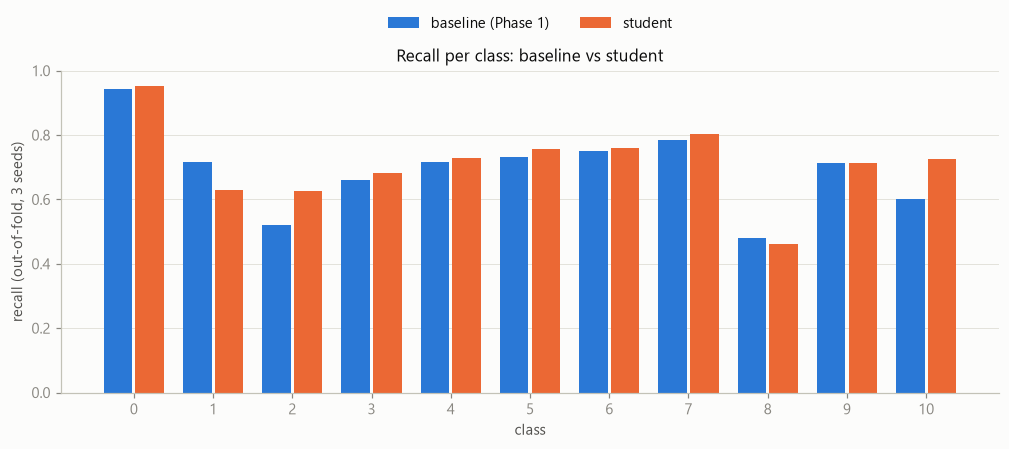

class,0,1,2,3,4,5,6,7,8,9,10
baseline (Phase 1),0.94,0.72,0.52,0.66,0.72,0.73,0.75,0.78,0.48,0.71,0.60
student,0.95,0.63,0.62,0.68,0.73,0.76,0.76,0.80,0.46,0.71,0.72


In [6]:
recall = pd.DataFrame({"baseline (Phase 1)": cv.per_class_recall(d.y[lab], base_oof.argmax(1)),
                       "student": cv.per_class_recall(d.y[lab], stud_oof[lab].argmax(1))})
recall.index.name = "class"
fig, ax = plt.subplots(figsize=(11, 3.8))
w = 0.4
for i, (name, color) in enumerate(zip(recall.columns, SERIES)):
    ax.bar(recall.index + (i - 0.5) * w, recall[name], width=w - 0.04, color=color, label=name)
ax.set_xticks(recall.index)
ax.set(xlabel="class", ylabel="recall (out-of-fold, 3 seeds)", title="Recall per class: baseline vs student", ylim=(0, 1))
ax.grid(axis="x", visible=False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.08), ncols=2)
plt.show()
display(recall.T.style.format("{:.2f}"))

**What this shows.**
- Over 3 seeds × 5 folds, the student reaches **0.708** balanced accuracy vs **0.682** for the baseline: **+0.026** run by run (standard error 0.010), higher in **12 of 15** runs.
- Plain accuracy rises from 0.775 to **0.792**. Clean rows improve (0.927 → 0.949), and so do the other deformed rows (0.781 → 0.800). **The far group does not improve** (0.592 → 0.595).
- **Per class:** large gains on two hard, rare classes, **class 2 (0.52 → 0.62)** and **class 10 (0.60 → 0.72)**, and small gains on classes 3, 5 and 7. **Class 1 drops (0.72 → 0.63)**, and class 8 stays the hardest (0.48 → 0.46).
- The baseline reproduces the Phase 1 numbers exactly (same folds and seeds).

**Decision:** the all-three-channel student replaces the Phase 1 baseline.

## 5. Final model and submission

`distill.fit_final` trains on all training rows:
- teachers on `G` of all 1284 labelled rows (3 seeds), which label the 792 unlabelled rows;
- out-of-fold teacher logits for the labelled rows (fixed folds, 3 seeds);
- 5 student seeds on `E` of all 2076 rows.

The test prediction averages the 5 students. Weights go to `checkpoints/phase3_student/` and the submission to `submissions/`
(both git-ignored).

In [7]:
t0 = time.time()
students, final_teacher = distill.fit_final(d.E, d.G, d.y, fold, CFG, CHOSEN, teacher_seeds=(0, 1, 2),
                                            student_seeds=(0, 1, 2, 3, 4))
proba_test = mlp.ensemble_proba(students, d.F)
pred_test = proba_test.argmax(1)
print(f"{time.time() - t0:.0f} s")

ckpt_dir = Path("checkpoints/phase3_student")
ckpt_dir.mkdir(parents=True, exist_ok=True)
for s, m in enumerate(students):
    torch.save(m.state_dict(), ckpt_dir / f"student_seed{s}.pt")
(ckpt_dir / "config.json").write_text(json.dumps({"mlp": CFG.__dict__, "student": CHOSEN.__dict__,
                                                  "teacher_seeds": [0, 1, 2], "student_seeds": [0, 1, 2, 3, 4]}, indent=1))

sub = pd.DataFrame({"ID": d.test_id.astype(int), "Label": pred_test.astype(int)})
assert len(sub) == 490 and sub["ID"].is_unique and sub["Label"].between(0, N_CLASSES - 1).all()
sub_path = Path("submissions") / "phase3_student_all_channels.csv"
sub_path.parent.mkdir(exist_ok=True)
sub.to_csv(sub_path, index=False)
print("wrote", sub_path)

phase1 = pd.read_csv("submissions/phase1_mlp_logit_adjusted.csv")
print(f"agreement with the Phase 1 submission: {(phase1['Label'].to_numpy() == pred_test).mean():.1%} of test rows")
mix = pd.DataFrame({"labelled train": np.bincount(d.y[lab], minlength=N_CLASSES) / lab.sum(),
                    "Phase 1 test predictions": np.bincount(phase1["Label"], minlength=N_CLASSES) / len(phase1),
                    "student test predictions": np.bincount(pred_test, minlength=N_CLASSES) / len(pred_test)})
mix.index.name = "class"
display(mix.T.style.format("{:.1%}"))

253 s
wrote submissions\phase3_student_all_channels.csv
agreement with the Phase 1 submission: 84.5% of test rows


class,0,1,2,3,4,5,6,7,8,9,10
labelled train,35.0%,3.6%,3.7%,7.1%,5.8%,9.0%,11.0%,7.6%,3.9%,10.3%,3.1%
Phase 1 test predictions,12.2%,5.9%,5.7%,9.6%,9.4%,11.8%,11.4%,10.8%,7.1%,9.2%,6.7%
student test predictions,11.6%,4.9%,5.5%,9.6%,10.4%,13.1%,11.2%,11.0%,7.1%,7.8%,7.8%


**What this shows.**
- The final students were trained on all 2076 rows, and the submission passed the format checks.
- It agrees with the Phase 1 submission on **84.5%** of test rows. The changes are targeted rather than a reshuffle.
- The predicted class mix stays close to uniform (class 0: 11.6%, every class between 4.9% and 13.1%), consistent with the label shift found in Phase 1.

## 6. Summary

| | CV balanced acc. | CV acc. | clean / deformed / far |
|---|---|---|---|
| Phase 1 baseline (MLP on E, logit-adjusted) | 0.682 | 0.775 | 0.927 / 0.781 / 0.592 |
| Teacher on G (cannot predict test; 1 seed) | 0.832 | 0.877 | 0.963 / 0.877 / 0.795 |
| **Student, all three channels** | **0.708** | **0.792** | **0.949 / 0.800 / 0.595** |

**What we learned**
1. **Generalized distillation works, but only modestly** (+0.026 balanced accuracy). The student cannot recover most of what `G` knows from `E` alone.
2. **The three channels add up.** Pseudo-labels on unlabelled rows, soft labels on labelled rows (out-of-fold) and the `G`-prediction head each help a little.
3. **Prior consistency matters.** Every soft loss needs the same logit-adjustment shift as the labelled-row loss; otherwise the class-0-heavy unlabelled rows undo it.
4. **The far group is still at about 0.59.** None of the channels helped it, even though the teacher scores 0.795 there. It is the largest remaining gap.

**Next**
- Upload `submissions/phase3_student_all_channels.csv` and record the score in `docs/experiment_log.md`.
- Remaining ideas, in order of expected value:
  - a stronger prior correction, to be checked on Kaggle;
  - a larger student ensemble;
  - targeted work on the far group.